# NISAR workflow (NASA Earthdata)
Same steps as `Biomass_Downloader.ipynb`, for the NISAR L-band products that NASA distributes through the Alaska Satellite Facility. The logic lives in the `biomass` package (`src/biomass`). Install once with `pip install -e ".[geo,dev]"`, edit only the configuration cell and run top to bottom.

It needs a NASA Earthdata Login token in `nasa_token.txt`, next to `token.txt` (https://urs.earthdata.nasa.gov > Generate Token; it lasts 60 days).

In [1]:
from pathlib import Path
from biomass import (NisarClient, SearchQuery, Downloader, nisar_items_table, assets_table,
                     footprint_map, inspect_gcov, plot_gcov, gcov_map)

# --- Configuration ---
QUERY = SearchQuery(
    collection="NISAR_L2_GCOV_PROVISIONAL_V1_1",   # the collection is the product type (see Explore)
    date_start="2025-10-28",                       # first provisional products
    date_end="2026-07-01",
    bbox=[-81.00, -20.00, -35.00, 10.00],          # [min_lon, min_lat, max_lon, max_lat]
    aoi_file=None,                                 # e.g. "my_area.geojson" (overrides bbox)
    max_items=10,                                  # results come oldest first
)
# Acquisition mode of the main band (frequency A); None accepts any
POLARISATION = "DH"                                # "SH"/"SV" one channel, "DH" HH+HV, "DV" VV+VH, "QP" all four;
                                                   # or a list, e.g. ["DH", "QP"] for everything with HH and HV
BANDWIDTH = None                                   # MHz: 5, 20, 40 or 77 (more bandwidth = finer range resolution)
BROWSE_ASSETS = ["browse_latlon"]                  # small preview images
PRODUCT_ASSETS = ["product"]                       # the .h5 file: about 5 GB each
OUTPUT_DIR = Path("../data/nisar")

client = NisarClient()
client.auth.access_token(); print("Token OK")

Token OK


## Explore

In [2]:
client.collections()

,id,title,extent.temporal.interval
0,NISAR_L0B_CRSD_PROVISIONAL_V1_1,NISAR Provisional Radar Raw Signal Calibration...,"[[2026-06-16T22:00:00.000Z, None]]"
1,NISAR_L1_RIFG_BETA_V1_1,NISAR Beta Range Doppler Wrapped Interferogram...,"[[2025-10-01T00:00:00.000Z, None]]"
2,NISAR_L1_RIFG_PROVISIONAL_V1_1,NISAR Provisional Range Doppler Wrapped Interf...,"[[2025-10-28T00:00:00.000Z, None]]"
3,NISAR_L1_ROFF_BETA_V1_1,NISAR Beta Range Doppler Pixel Offsets (Versio...,"[[2025-10-01T00:00:00.000Z, None]]"
4,NISAR_L1_ROFF_PROVISIONAL_V1_1,NISAR Provisional Range Doppler Pixel Offsets ...,"[[2025-10-28T00:00:00.000Z, None]]"
5,NISAR_L1_RSLC_BETA_V1_1,NISAR Beta Range Doppler Single Look Complex P...,"[[2025-10-01T00:00:00.000Z, None]]"
6,NISAR_L1_RSLC_PROVISIONAL_V1_1,NISAR Provisional Range Doppler Single Look Co...,"[[2025-10-28T00:00:00.000Z, None]]"
7,NISAR_L1_RUNW_BETA_V1_1,NISAR Beta Range Doppler Unwrapped Interferogr...,"[[2025-10-01T00:00:00.000Z, None]]"
8,NISAR_L1_RUNW_PROVISIONAL_V1_1,NISAR Provisional Range Doppler Unwrapped Inte...,"[[2025-10-28T00:00:00.000Z, None]]"
9,NISAR_L2_GCOV_BETA_V1_1,NISAR Beta Geocoded Polarimetric Covariance Pr...,"[[2025-10-01T00:00:00.000Z, None]]"


## Search

In [3]:
items = client.search(QUERY, polarisation=POLARISATION, bandwidth=BANDWIDTH)
nisar_items_table(items)

10 products fetched | 1171 match in total


,idx,id,start,orbit,track,frame,mode,pols,assets
0,0,NISAR_L2_PR_GCOV_004_025_D_083_4005_DHDH_A_202...,2025-10-30T22:45:54.000Z,descending,025,083,4005,DHDH,8
1,1,NISAR_L2_PR_GCOV_004_025_D_084_4005_DHDH_A_202...,2025-10-30T22:46:28.000Z,descending,025,084,4005,DHDH,8
2,2,NISAR_L2_PR_GCOV_004_046_A_167_2005_DHDH_A_202...,2025-11-01T10:31:15.000Z,ascending,046,167,2005,DHDH,8
3,3,NISAR_L2_PR_GCOV_004_046_A_168_2005_DHDH_A_202...,2025-11-01T10:31:49.000Z,ascending,046,168,2005,DHDH,8
4,4,NISAR_L2_PR_GCOV_004_046_A_169_2005_DHDH_A_202...,2025-11-01T10:32:22.000Z,ascending,046,169,2005,DHDH,8
5,5,NISAR_L2_PR_GCOV_004_046_A_170_2005_DHDH_A_202...,2025-11-01T10:32:56.000Z,ascending,046,170,2005,DHDH,8
6,6,NISAR_L2_PR_GCOV_004_046_A_175_2005_DHDH_A_202...,2025-11-01T10:35:43.000Z,ascending,046,175,2005,DHDH,8
7,7,NISAR_L2_PR_GCOV_004_054_D_083_4005_DHDH_A_202...,2025-11-01T23:02:33.000Z,descending,054,083,4005,DHDH,8
8,8,NISAR_L2_PR_GCOV_004_054_D_084_4005_DHDH_A_202...,2025-11-01T23:03:06.000Z,descending,054,084,4005,DHDH,8
9,9,NISAR_L2_PR_GCOV_004_061_A_006_4005_DHDH_A_202...,2025-11-02T09:58:00.000Z,ascending,061,006,4005,DHDH,8


In [4]:
footprint_map(items, QUERY)

## Download

In [5]:
assets_table(items[0])

,asset,media_type,href
0,browse_b_hvhv,image/jpeg,https://nisar.asf.earthdatacloud.nasa.gov/BROW...
1,browse_latlon,NaN,https://nisar.asf.earthdatacloud.nasa.gov/BROW...
2,thumbnail,NaN,https://nisar.asf.earthdatacloud.nasa.gov/BROW...
3,browse,NaN,https://nisar.asf.earthdatacloud.nasa.gov/BROW...
4,browse_a_hhhh,NaN,https://nisar.asf.earthdatacloud.nasa.gov/BROW...
5,browse_a_hvhv,NaN,https://nisar.asf.earthdatacloud.nasa.gov/BROW...
6,browse_b_hhhh,NaN,https://nisar.asf.earthdatacloud.nasa.gov/BROW...
7,product,NaN,https://nisar.asf.earthdatacloud.nasa.gov/NISA...


In [6]:
downloader = Downloader(client.auth, OUTPUT_DIR, item_folders=False)
browse = downloader.download(items, BROWSE_ASSETS)

  already exists, skipping: NISAR_L2_PR_GCOV_004_025_D_083_4005_DHDH_A_20251030T224554_20251030T224629_P05023_N_F_J_001_LATLON.png
  already exists, skipping: NISAR_L2_PR_GCOV_004_025_D_084_4005_DHDH_A_20251030T224628_20251030T224702_P05023_N_F_J_001_LATLON.png
  already exists, skipping: NISAR_L2_PR_GCOV_004_046_A_167_2005_DHDH_A_20251101T103115_20251101T103150_P05023_N_F_J_001_LATLON.png
  already exists, skipping: NISAR_L2_PR_GCOV_004_046_A_168_2005_DHDH_A_20251101T103149_20251101T103223_P05023_N_F_J_001_LATLON.png
  already exists, skipping: NISAR_L2_PR_GCOV_004_046_A_169_2005_DHDH_A_20251101T103222_20251101T103257_P05023_N_F_J_001_LATLON.png
  already exists, skipping: NISAR_L2_PR_GCOV_004_046_A_170_2005_DHDH_A_20251101T103256_20251101T103331_P05023_N_F_J_001_LATLON.png
  already exists, skipping: NISAR_L2_PR_GCOV_004_046_A_175_2005_DHDH_A_20251101T103543_20251101T103556_P05023_N_P_J_001_LATLON.png


NISAR_L2_PR_GCOV_004_054_D_083_4005_DHDH_A_20251101T230233_20251101T230307_P05023_N_F_J_001_LATLON.png:   0%| …

NISAR_L2_PR_GCOV_004_054_D_084_4005_DHDH_A_20251101T230306_20251101T230345_P05023_N_F_J_001_LATLON.png:   0%| …

NISAR_L2_PR_GCOV_004_061_A_006_4005_DHDH_A_20251102T095800_20251102T095835_P05023_N_F_J_001_LATLON.png:   0%| …


10 files in <project folder>\data\nisar


In [7]:
files = downloader.download(items[:1], PRODUCT_ASSETS)   # about 5 GB per product: start with one

  already exists, skipping: NISAR_L2_PR_GCOV_004_025_D_083_4005_DHDH_A_20251030T224554_20251030T224629_P05023_N_F_J_001.h5

1 files in <project folder>\data\nisar


## Inspect

In [8]:
inspect_gcov(files[0])

NISAR_L2_PR_GCOV_004_025_D_083_4005_DHDH_A_20251030T224554_20251030T224629_P05023_N_F_J_001
Band: L | orbit: Descending | look: Left | track 25 frame 83 | start: 2025-10-30T22:45:54.000000000
  frequency A: 33912 x 33264 px at 10 m | EPSG:32620 | terms: HHHH, HVHV
  frequency B: 4239 x 4158 px at 80 m | EPSG:32620 | terms: HHHH, HVHV


{'granuleId': 'NISAR_L2_PR_GCOV_004_025_D_083_4005_DHDH_A_20251030T224554_20251030T224629_P05023_N_F_J_001',
 'radarBand': 'L',
 'orbitPassDirection': 'Descending',
 'lookDirection': 'Left',
 'trackNumber': '25',
 'frameNumber': '83',
 'zeroDopplerStartTime': '2025-10-30T22:45:54.000000000',
 'productVersion': '1.0.11',
 'frequencies': {'A': {'terms': ['HHHH', 'HVHV'],
   'shape': (33264, 33912),
   'epsg': 32620,
   'spacing_m': 10.0},
  'B': {'terms': ['HHHH', 'HVHV'],
   'shape': (4158, 4239),
   'epsg': 32620,
   'spacing_m': 80.0}}}

## Visualize
`plot_gcov` shows every backscatter term of one file (gamma0 in dB, on its UTM grid). `gcov_map` lays the downloaded files over a map: `band="rgb"` is a colour composite (R=HHHH, G=HVHV, B=VVVV, or HHHH/HVHV when there is no VV), or pass `"HHHH"`, `"HVHV"`... for a single term. Both read the coarsest grid in the file by default; pass `frequency="A"` for the main 10 m one.

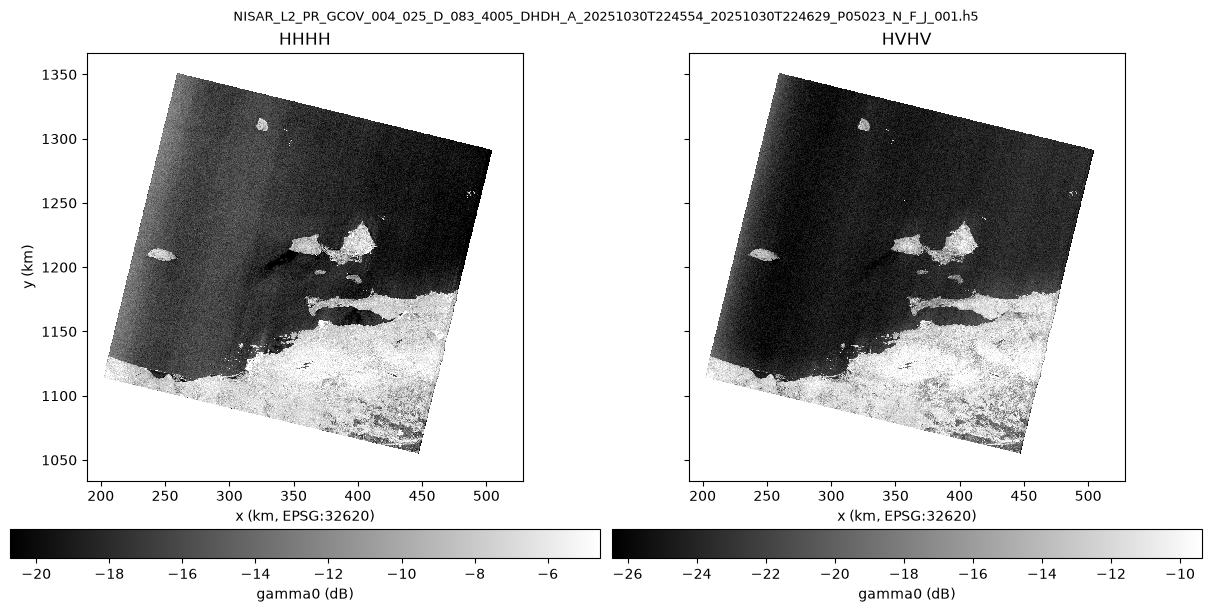

In [9]:
h5_files = sorted(OUTPUT_DIR.glob("*.h5"))
plot_gcov(h5_files[0]);


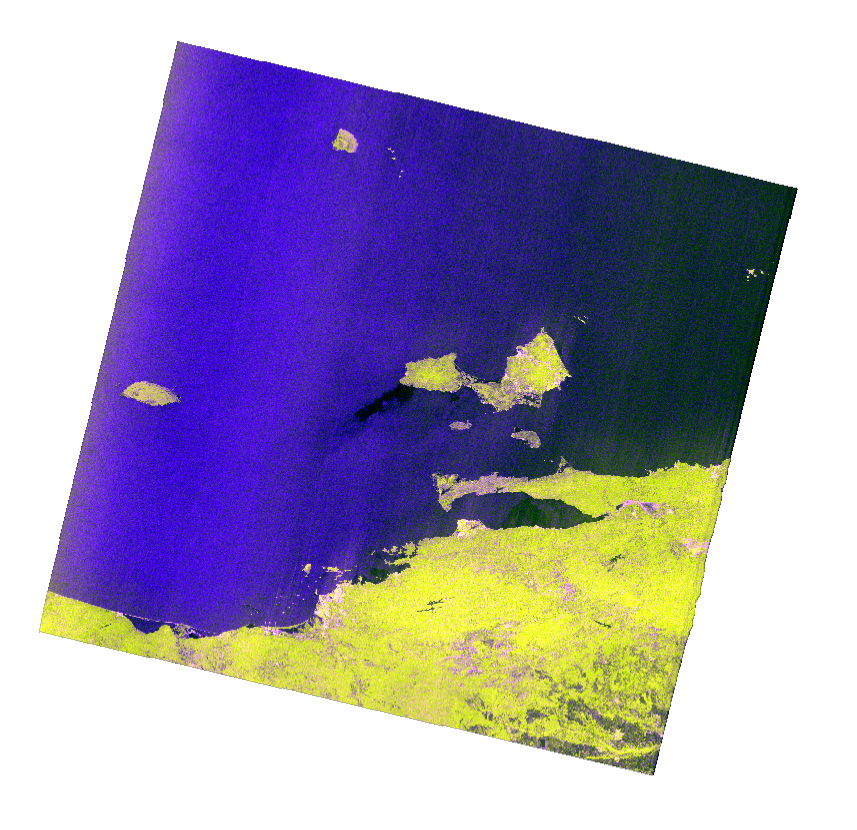

In [10]:
gcov_map(h5_files)   # one layer per file; toggle them with the control in the top-right corner